# UAE Real Estate 10-Year Trend Prediction
Use Python 3.11. Put this notebook and `real_estate_10yr_prediction.csv` in a new folder and choose **Run All**. Rename the supplied CSV if its name ends in `(1)`. The notebook creates the model, the two Python helper scripts, and `app.py` in that folder.

The target is the label recorded for a household profile. The file contains no dated property prices to verify the ten-year outcome.

## 1. Import libraries
If needed, uncomment the installation line and restart the kernel after installation.

In [1]:
# %pip install pandas==2.2.3 numpy==2.2.6 scipy==1.15.3 scikit-learn==1.7.2 joblib==1.5.2 streamlit==1.51.0 matplotlib==3.10.7 seaborn==0.13.2 plotly==6.4.0
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from time import perf_counter

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score

## 2. Load the dataset

In [3]:
df = pd.read_csv("real_estate_10yr_prediction.csv", low_memory=False)
df.head()

,Record_ID,Age,Gender,Marital_Status,Dependents,Education_Level,City_Emirate,Residency_Status,Current_Housing,Years_At_Residence,Employment_Sector,Annual_Income_AED,Monthly_Savings_AED,Debt_To_Income_Ratio,Credit_Score,Existing_Properties,Preferred_Property_Type,Estimated_Budget_AED,Mortgage_Interest_Rate_Pct,RealEstate_10Yr_Trend
0,RE-1069438,38.0,male,Single,0.0,High School,Abu Dhabi,Expat_LongTerm,Owns_Outright,0.0,Salaried_Private,106307.5,3389.79,0.184,770.0,0.0,Apartment,498000,6.44,Increased
1,RE-1134626,34.0,Male,Divorced,2.0,High School,Ras Al Khaimah,Expat_LongTerm,Renting,6.7,Salaried_Private,143942.2,3965.85,0.548,683.0,NaN,Villa,512000,3.85,Increased
2,RE-1207901,25.0,Female,Single,5.0,Bachelor,Sharjah,Expat_LongTerm,Family_Home,6.6,NaN,601270.37,16309.13,NaN,848.0,0.0,Apartment,2534000,5.04,Increased
3,RE-1223123,30.0,NaN,Married,5.0,Master,Sharjah,Expat_Standard,Family_Home,13.6,Unemployed,211362.94,1931.54,0.130,648.0,0.0,NaN,908000,5.42,Dropped
4,RE-1015664,0.0,Female,Married,2.0,Bachelor,Dubai,Expat_Standard,Owns_Outright,5.1,Salaried_Gov,113348.94,3466.14,0.090,716.0,0.0,Villa,NaN,5.14,Dropped


## 3. Understand the data

In [4]:
print(df.shape)
df.info()

(300000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Record_ID                   300000 non-null  object 
 1   Age                         276893 non-null  float64
 2   Gender                      277094 non-null  object 
 3   Marital_Status              279032 non-null  object 
 4   Dependents                  287374 non-null  float64
 5   Education_Level             272189 non-null  object 
 6   City_Emirate                276764 non-null  object 
 7   Residency_Status            268589 non-null  object 
 8   Current_Housing             272005 non-null  object 
 9   Years_At_Residence          286660 non-null  float64
 10  Employment_Sector           284713 non-null  object 
 11  Annual_Income_AED           285681 non-null  object 
 12  Monthly_Savings_AED         269355 non-null  float64
 13  D

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,300000,294113,RE-1203269,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,276893.0,NaN,NaN,NaN,49.001206,39.139485,-5.0,34.0,48.0,61.0,999.0
Gender,277094,7,Female,116521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,279032,6,Married,134066,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,287374.0,NaN,NaN,NaN,1.566732,1.913948,-1.0,0.0,1.0,2.0,15.0
Education_Level,272189,7,Bachelor,123212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City_Emirate,276764,10,Dubai,97117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residency_Status,268589,5,Expat_Standard,94031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_Housing,272005,6,Renting,149365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Years_At_Residence,286660.0,NaN,NaN,NaN,4.499886,4.487268,0.0,1.3,3.1,6.2,57.2


In [6]:
target = "RealEstate_10Yr_Trend"
print("Duplicate rows:", df.duplicated().sum())
print("Missing targets:", df[target].isna().sum())
df.isna().sum()

Duplicate rows: 5887
Missing targets: 26442


Record_ID                         0
Age                           23107
Gender                        22906
Marital_Status                20968
Dependents                    12626
Education_Level               27811
City_Emirate                  23236
Residency_Status              31411
Current_Housing               27995
Years_At_Residence            13340
Employment_Sector             15287
Annual_Income_AED             14319
Monthly_Savings_AED           30645
Debt_To_Income_Ratio          19646
Credit_Score                  20786
Existing_Properties           23448
Preferred_Property_Type       26365
Estimated_Budget_AED          31855
Mortgage_Interest_Rate_Pct    14322
RealEstate_10Yr_Trend         26442
dtype: int64

In [7]:
for col in df.select_dtypes("object"):
    if df[col].nunique() < 25:
        print(col, df[col].dropna().unique())

Gender ['male' 'Male' 'Female' 'F' 'M' 'female' 'Unknown']
Marital_Status ['Single' 'Divorced' 'Married' 'Widowed' 'single' 'MARRIED']
Education_Level ['High School' 'Bachelor' 'Master' 'bachelor' 'PhD' 'Diploma' 'HS']
City_Emirate ['Abu Dhabi' 'Ras Al Khaimah' 'Sharjah' 'Dubai' 'Ajman' 'ABU DHABI'
 'dubai' 'Fujairah' 'Dxb' 'Umm Al Quwain']
Residency_Status ['Expat_LongTerm' 'Expat_Standard' 'Citizen' 'Resident' 'Golden_Visa']
Current_Housing ['Owns_Outright' 'Renting' 'Family_Home' 'Owns_Mortgage' 'Renting ' 'rent']
Employment_Sector ['Salaried_Private' 'Unemployed' 'Salaried_Gov' 'Business_Owner' 'Retired'
 'Self_Employed']
Preferred_Property_Type ['Apartment' 'Villa' 'Studio' 'Townhouse' 'apt' 'VILLA' 'Penthouse']
RealEstate_10Yr_Trend ['Increased' 'Dropped' 'increased' 'dropped' 'Drop Down' 'INCREASED'
 'DROPPED' 'Increase ']


## 4. Clean the data
Remove exact repeats, standardize the target, and drop unknown targets. Leave missing inputs for the training pipeline.

In [8]:
df = df.drop_duplicates().copy()
df[target] = df[target].str.strip().str.lower()
df[target] = df[target].map({"increase":"Increased", "increased":"Increased",
                            "drop down":"Dropped", "dropped":"Dropped"})
df = df.dropna(subset=[target])
print("Labeled rows:", len(df), "| Repeated IDs:", df.Record_ID.duplicated().sum())
df[target].value_counts()

Labeled rows: 268187 | Repeated IDs: 0


RealEstate_10Yr_Trend
Dropped      166562
Increased    101625
Name: count, dtype: int64

### Fix numbers and categories
Save this cleaning rule so the deployed model can use it too. Negative financial values and invalid counts become missing. The working assumptions are adult ages of 18–120 and credit scores of 300–900.

In [9]:
%%writefile cleaning.py
import numpy as np
import pandas as pd

def clean_inputs(X):
    X = X.copy()
    for col in ["Annual_Income_AED", "Estimated_Budget_AED", "Mortgage_Interest_Rate_Pct"]:
        text = X[col].astype("string").str.replace(r"AED|,|%", "", regex=True).str.strip()
        X[col] = pd.to_numeric(text, errors="coerce").astype(float)

    for col in X.select_dtypes("number"):
        X[col] = X[col].where(X[col].ge(0) & np.isfinite(X[col]))
    for col in ["Age", "Dependents", "Existing_Properties", "Credit_Score"]:
        if col in X:
            X[col] = X[col].where(X[col] % 1 == 0)
    X["Credit_Score"] = X.Credit_Score.where(X.Credit_Score.between(300, 900))
    X["Mortgage_Interest_Rate_Pct"] = X.Mortgage_Interest_Rate_Pct.where(X.Mortgage_Interest_Rate_Pct <= 100)
    if "Age" in X:
        X["Age"] = X.Age.where(X.Age.between(18, 120))
        X.loc[X.Years_At_Residence > X.Age, "Years_At_Residence"] = np.nan

    aliases = {"City_Emirate":{"dxb":"dubai"}, "Current_Housing":{"rent":"renting"},
               "Preferred_Property_Type":{"apt":"apartment"}, "Education_Level":{"hs":"high school"},
               "Gender":{"m":"male", "f":"female"}}
    for col in X.select_dtypes("object"):
        X[col] = X[col].str.strip().str.lower().replace(aliases.get(col, {}))
        X[col] = X[col].replace({"unknown":np.nan, "":np.nan})
    return X

Writing cleaning.py


In [10]:
from cleaning import clean_inputs

raw = df.drop(columns=["Record_ID", target])
clean = clean_inputs(raw)
pd.DataFrame({"Missing before": raw.isna().sum(), "Missing after rules": clean.isna().sum()})

,Missing before,Missing after rules
Age,20619,22223
Gender,20479,25502
Marital_Status,18734,18734
Dependents,11256,13851
Education_Level,24940,24940
City_Emirate,20804,20804
Residency_Status,28146,28146
Current_Housing,25054,25054
Years_At_Residence,11952,12137
Employment_Sector,13622,13622


### Check outliers
The IQR rule flags unusual values. Keep plausible extremes such as high income; a large value alone does not prove an error.

In [11]:
numbers = clean.select_dtypes("number")
q1 = numbers.quantile(0.25)
q3 = numbers.quantile(0.75)
iqr = q3 - q1
((numbers < q1 - 1.5 * iqr) | (numbers > q3 + 1.5 * iqr)).sum()

Age                               0
Dependents                     2652
Years_At_Residence            12382
Annual_Income_AED             13463
Monthly_Savings_AED           13436
Debt_To_Income_Ratio           2297
Credit_Score                   1157
Existing_Properties           12265
Estimated_Budget_AED          12665
Mortgage_Interest_Rate_Pct     1795
dtype: int64

## 5. Explore the data
These first plots describe data quality and class balance. We explore relationships with the target after setting aside the test rows.

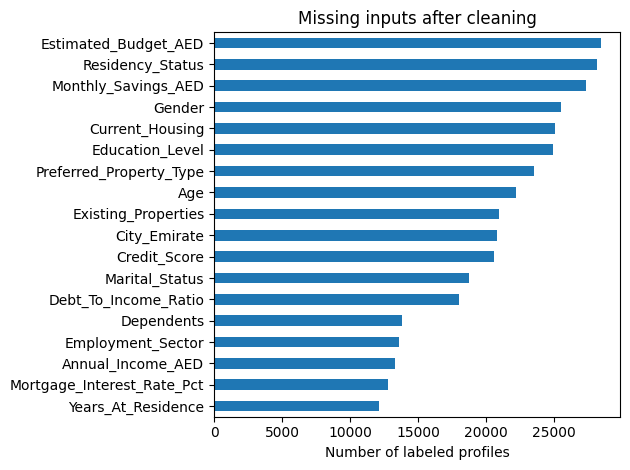

In [12]:
clean.isna().sum().sort_values().plot.barh(title="Missing inputs after cleaning")
plt.xlabel("Number of labeled profiles")
plt.tight_layout()
plt.show()

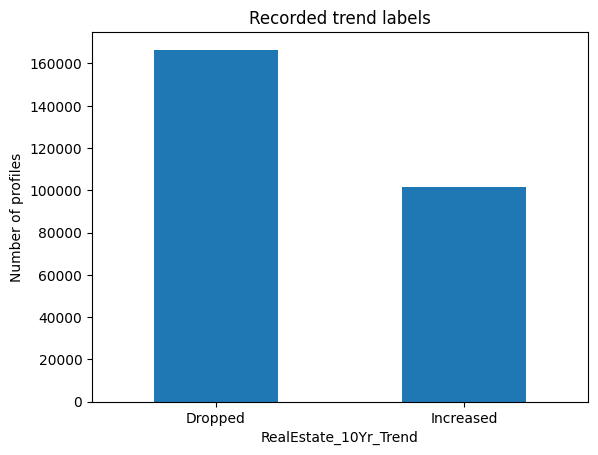

In [13]:
df[target].value_counts().plot.bar(title="Recorded trend labels", rot=0)
plt.ylabel("Number of profiles")
plt.show()

## 6. Create financial features
Keep the same six features as the working model. The first two are income ratios. The other four estimate debt payments, monthly income after debt, years to save the budget, and monthly interest if the entire budget were borrowed. Zero income or zero savings makes its ratio undefined.

In the supplied working notebook, adding the four extra features raised five-fold macro F1 from 0.7144 to 0.7189 at the same 15-leaf setting. This version keeps those features.

In [14]:
%%writefile financial_features.py
def add_features(X):
    X = X.copy()
    income = X.Annual_Income_AED
    savings = X.Monthly_Savings_AED * 12
    budget = X.Estimated_Budget_AED

    X["Savings_to_income"] = savings / income.where(income > 0)
    X["Budget_to_income"] = budget / income.where(income > 0)
    X["Monthly_debt_AED"] = income / 12 * X.Debt_To_Income_Ratio
    X["Income_after_debt_AED"] = income / 12 - X.Monthly_debt_AED
    X["Years_to_save_budget"] = budget / savings.where(savings > 0)
    X["Monthly_interest_AED"] = budget * X.Mortgage_Interest_Rate_Pct / 100 / 12
    return X

Writing financial_features.py


In [15]:
from financial_features import add_features
add_features(clean.head()).iloc[:, -6:].round(2)

,Savings_to_income,Budget_to_income,Monthly_debt_AED,Income_after_debt_AED,Years_to_save_budget,Monthly_interest_AED
0,0.38,4.68,1630.05,7228.91,12.24,2672.60
1,0.33,3.56,6573.36,5421.82,10.76,1642.67
2,0.33,4.21,NaN,NaN,12.95,10642.80
3,0.11,4.30,2289.77,15323.81,39.17,4101.13
4,0.37,NaN,850.12,8595.63,NaN,NaN


## 7. Split input and output
Use the working model’s 11 input fields. The record ID and direct demographic fields stay out of the model.

In [16]:
categories = ["City_Emirate", "Current_Housing", "Employment_Sector", "Preferred_Property_Type"]
numbers = ["Annual_Income_AED", "Monthly_Savings_AED", "Debt_To_Income_Ratio", "Credit_Score",
           "Existing_Properties", "Estimated_Budget_AED", "Mortgage_Interest_Rate_Pct"]
X = raw[categories + numbers]
y = df[target]

## 8. Split training and testing data
Stratification keeps the class proportions similar. Reserve the test rows until the final evaluation.

In [17]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(x_train))
print("Testing rows:", len(x_test))

Training rows: 214549
Testing rows: 53638


### Explore the training profiles

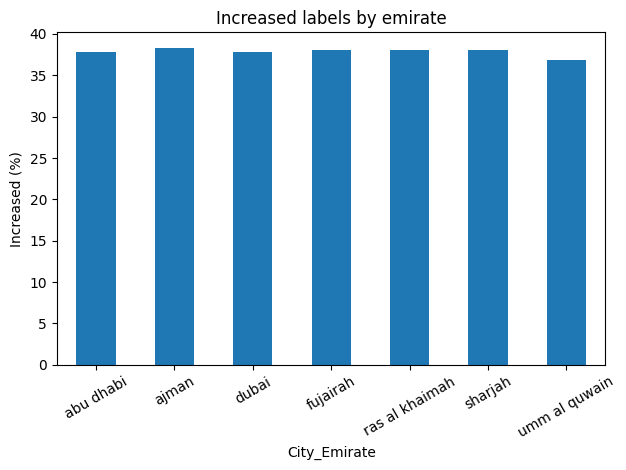

In [18]:
train = clean.loc[x_train.index].copy()
train["Increased"] = y_train == "Increased"
emirates = train.groupby("City_Emirate").Increased.mean().mul(100)
emirates.plot.bar(title="Increased labels by emirate", ylabel="Increased (%)", rot=30)
plt.tight_layout()
plt.show()

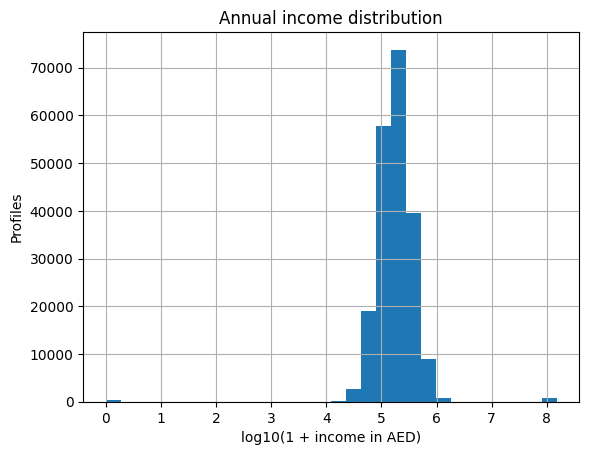

In [19]:
np.log10(1 + train.Annual_Income_AED).hist(bins=30)
plt.title("Annual income distribution")
plt.xlabel("log10(1 + income in AED)")
plt.ylabel("Profiles")
plt.show()

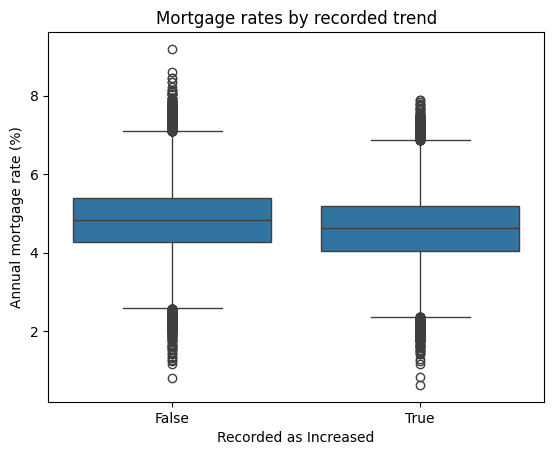

In [20]:
sns.boxplot(data=train, x="Increased", y="Mortgage_Interest_Rate_Pct")
plt.title("Mortgage rates by recorded trend")
plt.ylabel("Annual mortgage rate (%)")
plt.xlabel("Recorded as Increased")
plt.show()

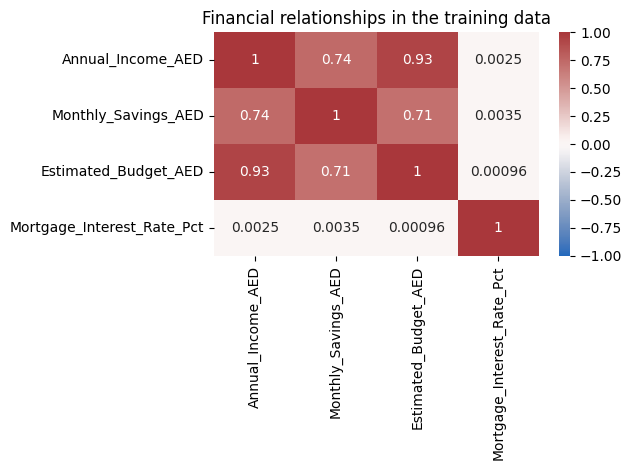

In [21]:
finance = ["Annual_Income_AED", "Monthly_Savings_AED", "Estimated_Budget_AED", "Mortgage_Interest_Rate_Pct"]
sns.heatmap(train[finance].corr(method="spearman"), annot=True, cmap="vlag", vmin=-1, vmax=1)
plt.title("Financial relationships in the training data")
plt.tight_layout()
plt.show()

## 9. Encode and scale
Define the preprocessing steps here. Every model fits them on its own training rows. During cross-validation, even the median and the most common category are learned again inside each fold.

In [22]:
extra = ["Savings_to_income", "Budget_to_income", "Monthly_debt_AED",
         "Income_after_debt_AED", "Years_to_save_budget", "Monthly_interest_AED"]

numeric_steps = Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())])
category_steps = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                           ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer([("numbers", numeric_steps, numbers + extra),
                                 ("categories", category_steps, categories)])

In [23]:
# A single pipeline keeps training, validation and app predictions consistent.
model = Pipeline([("clean", FunctionTransformer(clean_inputs)),
                  ("features", FunctionTransformer(add_features)),
                  ("preprocess", preprocessor),
                  ("classifier", LogisticRegression(max_iter=500))])

## 10. Train and compare models
Use the same five models as before. Compare them on a validation split inside the training data. A 12,000-row training sample keeps the classroom comparison quick.

In [24]:
x_small, _, y_small, _ = train_test_split(x_train, y_train, train_size=12000, stratify=y_train, random_state=42)
x_fit, x_valid, y_fit, y_valid = train_test_split(x_small, y_small, test_size=.2, stratify=y_small, random_state=42)

In [25]:
models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=500),
    "Decision tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=25, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=40, max_depth=10, random_state=42),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=75, max_leaf_nodes=15, random_state=42)
}

In [26]:
results = []
for name, classifier in models.items():
    model.set_params(classifier=classifier)
    start = perf_counter()
    model.fit(x_fit, y_fit)
    seconds = perf_counter() - start
    pred = model.predict(x_valid)
    prob = model.predict_proba(x_valid)[:, 1]
    print(name)
    print(classification_report(y_valid, pred, digits=3, zero_division=0))
    print(confusion_matrix(y_valid, pred, labels=["Dropped", "Increased"]))
    results.append([name, model.score(x_fit, y_fit), accuracy_score(y_valid, pred),
                    f1_score(y_valid, pred, average="macro"), roc_auc_score(y_valid == "Increased", prob), seconds])

Dummy
              precision    recall  f1-score   support

     Dropped      0.621     1.000     0.766      1491
   Increased      0.000     0.000     0.000       909

    accuracy                          0.621      2400
   macro avg      0.311     0.500     0.383      2400
weighted avg      0.386     0.621     0.476      2400

[[1491    0]
 [ 909    0]]
Logistic regression
              precision    recall  f1-score   support

     Dropped      0.747     0.872     0.805      1491
   Increased      0.711     0.516     0.598       909

    accuracy                          0.737      2400
   macro avg      0.729     0.694     0.701      2400
weighted avg      0.733     0.737     0.726      2400

[[1300  191]
 [ 440  469]]
Decision tree
              precision    recall  f1-score   support

     Dropped      0.756     0.826     0.790      1491
   Increased      0.664     0.563     0.610       909

    accuracy                          0.727      2400
   macro avg      0.710     0.695 

In [27]:
scores = pd.DataFrame(results, columns=["Model", "Train accuracy", "Validation accuracy", "Macro F1", "ROC-AUC", "Fit seconds"])
scores.round(3)

,Model,Train accuracy,Validation accuracy,Macro F1,ROC-AUC,Fit seconds
0,Dummy,0.621,0.621,0.383,0.500,0.072
1,Logistic regression,0.749,0.737,0.701,0.789,0.092
2,Decision tree,0.757,0.727,0.700,0.771,0.172
3,Random forest,0.827,0.740,0.700,0.785,0.633
4,Gradient boosting,0.786,0.754,0.723,0.797,0.333


## 11. Cross-validation
Use five stratified folds on the same training sample. Macro F1 gives both labels equal weight. Large train–validation gaps in the comparison above suggest overfitting.

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = {}
for name, classifier in models.items():
    model.set_params(classifier=classifier)
    folds[name] = cross_val_score(model, x_small, y_small, cv=cv, scoring="f1_macro")

In [29]:
fold_scores = pd.DataFrame(folds, index=["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"]).T
fold_scores["Mean"] = fold_scores.iloc[:, :5].mean(axis=1)
fold_scores["SD"] = fold_scores.iloc[:, :5].std(axis=1, ddof=0)
fold_scores.round(4)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
Dummy,0.3832,0.3832,0.3832,0.3830,0.3830,0.3831,0.0001
Logistic regression,0.7063,0.7001,0.7141,0.7148,0.7248,0.7120,0.0084
Decision tree,0.6794,0.6867,0.6949,0.6829,0.7105,0.6909,0.0111
Random forest,0.7024,0.6835,0.7115,0.6998,0.7113,0.7017,0.0102
Gradient boosting,0.7124,0.7062,0.7245,0.7211,0.7304,0.7189,0.0086


## 12. Tune with GridSearchCV
Keep the existing gradient boosting model. Repeat its original two leaf settings on training folds to demonstrate the teacher’s tuning step.

In [30]:
model.set_params(classifier=models["Gradient boosting"])
grid = GridSearchCV(model, {"classifier__max_leaf_nodes":[7, 15]}, cv=cv, scoring="f1_macro")
grid.fit(x_small, y_small)
print("Selected setting:", grid.best_params_)
pd.DataFrame(grid.cv_results_)[["param_classifier__max_leaf_nodes", "mean_test_score", "std_test_score"]].round(4)

Selected setting: {'classifier__max_leaf_nodes': 15}


,param_classifier__max_leaf_nodes,mean_test_score,std_test_score
0,7,0.7174,0.0112
1,15,0.7189,0.0086


## 13. Evaluate the final model
Fit the chosen configuration on all training rows. Use the untouched 20% test set once to measure agreement with the recorded labels.

In [31]:
final_model = grid.best_estimator_
final_model.fit(x_train, y_train)
pred = final_model.predict(x_test)
prob = final_model.predict_proba(x_test)[:, 1]

In [32]:
print(classification_report(y_test, pred, digits=3))
print("Train accuracy:", round(final_model.score(x_train, y_train), 4))
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))
print("Test macro F1:", round(f1_score(y_test, pred, average="macro"), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test == "Increased", prob), 4))
pd.DataFrame(confusion_matrix(y_test, pred), index=["Actual Dropped","Actual Increased"],
             columns=["Predicted Dropped","Predicted Increased"])

              precision    recall  f1-score   support

     Dropped      0.767     0.870     0.815     33313
   Increased      0.727     0.567     0.637     20325

    accuracy                          0.755     53638
   macro avg      0.747     0.718     0.726     53638
weighted avg      0.752     0.755     0.748     53638

Train accuracy: 0.7552
Test accuracy: 0.7551
Test macro F1: 0.7262
Test ROC-AUC: 0.8146


,Predicted Dropped,Predicted Increased
Actual Dropped,28977,4336
Actual Increased,8798,11527


### Check errors across groups
Among profiles actually labeled Increased, what share did the model miss? Demographic fields are excluded from training, but correlated inputs may still produce different error rates.

On this run, the model identified 56.7% of the test profiles labeled Increased. A predicted drop can therefore miss a recorded increase.

In [33]:
audit = clean.loc[x_test.index, ["Gender", "Residency_Status"]].copy()
audit["Missed increase"] = pred == "Dropped"
for col in ["Gender", "Residency_Status"]:
    display(audit[y_test == "Increased"].groupby(col, dropna=False)["Missed increase"].agg(["size", "mean"]).round(3))

,size,mean
Gender,,
female,9231,0.434
male,9178,0.432
NaN,1916,0.433


,size,mean
Residency_Status,,
citizen,3884,0.466
expat_longterm,6854,0.467
expat_standard,4654,0.349
golden_visa,2100,0.468
resident,674,0.329
NaN,2159,0.441


### Which inputs mattered?
Shuffle each raw input on a small holdout sample. A larger drop in macro F1 indicates greater model reliance on that input.

In [34]:
from sklearn.inspection import permutation_importance
sample = x_test.sample(1000, random_state=42)
importance = permutation_importance(final_model, sample, y_test.loc[sample.index],
                                    scoring="f1_macro", n_repeats=2, random_state=42)
pd.Series(importance.importances_mean, index=X.columns).sort_values(ascending=False).round(3)

Annual_Income_AED             0.106
Credit_Score                  0.034
Debt_To_Income_Ratio          0.029
Current_Housing               0.028
Mortgage_Interest_Rate_Pct    0.025
Estimated_Budget_AED          0.019
Monthly_Savings_AED           0.017
Employment_Sector             0.000
City_Emirate                  0.000
Preferred_Property_Type       0.000
Existing_Properties           0.000
dtype: float64

## 14. Prepare the deployment pipeline
The evaluated model already contains cleaning, all six features, the fitted imputers, scaler, encoder and classifier. Use this same fitted pipeline for the app.

In [35]:
deployment_pipeline = final_model
list(deployment_pipeline.named_steps)

['clean', 'features', 'preprocess', 'classifier']

## 15. Save and load the model

In [36]:
joblib.dump(deployment_pipeline, "real_estate_model.pkl", compress=3)
classifier = joblib.load("real_estate_model.pkl")

## 16. Try a sample prediction
Change one value and run the cell again to see its effect.

In [37]:
example = pd.DataFrame([{
    "City_Emirate":"dubai", "Current_Housing":"renting", "Employment_Sector":"salaried_private",
    "Preferred_Property_Type":"apartment", "Annual_Income_AED":180000, "Monthly_Savings_AED":4000,
    "Debt_To_Income_Ratio":0.30, "Credit_Score":700, "Existing_Properties":0,
    "Estimated_Budget_AED":700000, "Mortgage_Interest_Rate_Pct":4.5
}])
print("Predicted trend:", classifier.predict(example)[0])
pd.Series(classifier.predict_proba(example)[0], index=classifier.classes_, name="Probability")

Predicted trend: Dropped


Dropped      0.65996
Increased    0.34004
Name: Probability, dtype: float64

## 17. Create the Streamlit app
The app uses the categories learned during training. It loads the saved model once and accepts the same 11 inputs as the sample prediction.

In [38]:
%%writefile app.py
import joblib
import pandas as pd
import streamlit as st

@st.cache_resource
def load_model():
    return joblib.load("real_estate_model.pkl")

model = load_model()
st.title("UAE Real Estate Trend Prediction")

values = {}
fields = ["City_Emirate", "Current_Housing", "Employment_Sector", "Preferred_Property_Type"]
options = model.named_steps["preprocess"].named_transformers_["categories"]["encode"].categories_
with st.form("profile"):
    for field, choices in zip(fields, options):
        values[field] = st.selectbox(field.replace("_", " "), choices)
    values["Annual_Income_AED"] = st.number_input("Annual income (AED)", min_value=0, value=180000)
    values["Monthly_Savings_AED"] = st.number_input("Monthly savings (AED)", min_value=0, value=4000)
    values["Debt_To_Income_Ratio"] = st.number_input("Debt-to-income ratio", min_value=0.0, value=0.30)
    values["Credit_Score"] = st.number_input("Credit score", 300, 900, 700)
    values["Existing_Properties"] = st.number_input("Existing properties", min_value=0, value=0)
    values["Estimated_Budget_AED"] = st.number_input("Property budget (AED)", min_value=0, value=700000)
    values["Mortgage_Interest_Rate_Pct"] = st.slider("Annual mortgage rate (%)", 0.0, 100.0, 4.5)
    submitted = st.form_submit_button("Predict")

if submitted:
    profile = pd.DataFrame([values])
    st.subheader("Predicted trend: " + model.predict(profile)[0])
    probabilities = pd.Series(model.predict_proba(profile)[0], index=model.classes_)
    st.write("Model probabilities (%)")
    st.bar_chart(probabilities.mul(100))

Writing app.py


## 18. Create requirements.txt
These are the app dependencies for Python 3.11. For notebook training and plots, use the packages in section 1.

In [39]:
%%writefile requirements.txt
pandas==2.2.3
numpy==2.2.6
scikit-learn==1.6.1
plotly==6.4.0
streamlit==1.51.0
joblib==1.5.2
imbalanced-learn==0.14.0

Writing requirements.txt


### Run the app
From the folder containing this notebook and the generated files:
```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

For GitHub and Streamlit Community Cloud, keep `app.py`, `cleaning.py`, `financial_features.py`, `real_estate_model.pkl` and `requirements.txt` together. Select your project repository, branch `main`, entry point `app.py`, and Python 3.11. Public deployment still requires your account and a verified URL.

**Student work.** Add your own business objective, team contributions, result interpretation, data source/license and approval evidence to the README and report. The original data includes an ID among its 20 columns. If synthetic, confirm prior written instructor approval. Verify permission before sharing any records, including notebook previews.

**AI coding record.** ChatGPT helped simplify and run the Python notebook, retain the feature formulas, and verify model loading and local app predictions. Declare coding assistance in your own words.